<a href="https://colab.research.google.com/github/Neltrin22/PNL-Proyecto2/blob/main/Proyecto_2_PLN_UdeA_Nelson_Puerta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loguearse en Hugging

In [ ]:
from huggingface_hub import login
login()          # pega el token cuando lo pida; queda guardado en el runtime


Instalar librerias

In [ ]:
!pip install -q -U transformers datasets evaluate accelerate rouge_score seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


Montar drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
OUT = "/content/drive/MyDrive/PLN/Proyecto2"
os.makedirs(OUT, exist_ok=True)


Mounted at /content/drive


# **Problema 1 Clasificación**

In [ ]:
from datasets import load_dataset
ds1 = load_dataset("PolyAI/banking77")     # cambia por el id que elijas
print(ds1)                                 # splits y número de filas
print(ds1["train"][0])                     # una fila real, con sus columnas


README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 3080
    })
})
{'text': 'I am still waiting on my card?', 'label': 11}


## Tarea 1 — Detección de intención en consultas de banca (BANKING77)

- **Dataset:** PolyAI/banking77 (Hugging Face) — https://huggingface.co/datasets/PolyAI/banking77
- **Tipo de problema:** sequence classification (clasificación multiclase, 77 etiquetas).
- **Dominio:** banca digital / atención al cliente (consultas escritas por usuarios).
- **Utilidad:** enrutar automáticamente un mensaje al área correcta (tarjetas, transferencias,
  top-ups…), reducir el tiempo de primera respuesta y alimentar un asistente virtual.
- **Entrada:** una consulta corta en lenguaje natural ("¿por qué no me aparece el pago?").
- **Salida:** una intención entre 77 posibles (`card_arrival`, `lost_or_stolen_card`, …).
- **Tamaño:** 10 003 train, 3 080 test; sin validación → se parte un 10 % del train.
- **Balance de clases:** ~130 ejemplos por clase en train (razonablemente balanceado).
- **Longitud:** media ≈ 12 palabras → `max_length = 64` es suficiente.
- **Idioma:** inglés. **Licencia:** CC-BY-4.0.
- **Reto:** 77 clases muy parecidas entre sí (`pending_transfer` vs. `failed_transfer`);
  distinguirlas exige vocabulario fino, no solo bolsa de palabras.


Exploracion del dataset

(10003, 2) {'text': 0, 'label': 0} 0
label
15    187
28    182
6     181
75    180
19    177
     ... 
41     82
18     61
10     59
72     41
23     35
Name: count, Length: 77, dtype: int64
count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: n_palabras, dtype: float64


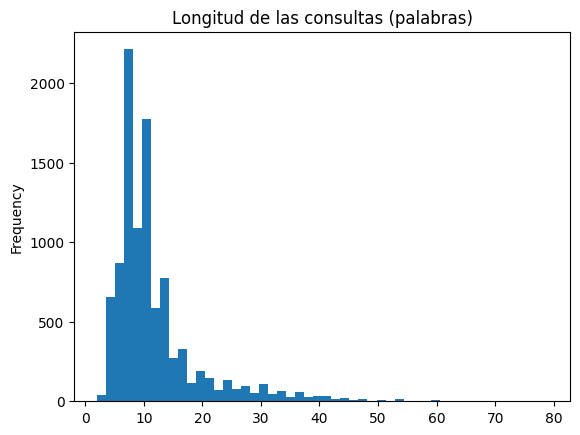

— card_arrival → I am still waiting on my card?
— card_arrival → What can I do if my card still hasn't arrived after 2 weeks?
— card_arrival → I have been waiting over a week. Is the card still coming?


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
df1 = ds1["train"].to_pandas()
print(df1.shape, df1.isna().sum().to_dict(), df1.duplicated(subset="text").sum())
print(df1["label"].value_counts())                 # 77 clases: revisa el mínimo por clase
df1["n_palabras"] = df1["text"].str.split().str.len()
print(df1["n_palabras"].describe())
df1["n_palabras"].plot(kind="hist", bins=50, title="Longitud de las consultas (palabras)")
plt.show()

# Obtenemos los nombres reales de las etiquetas a partir de las características del dataset
nombres = ds1["train"].features["label"].names

for i in range(3):
    # Usamos el id de la etiqueta (df["label"][i]) para buscar su nombre correspondiente
    print("—", nombres[df1["label"][i]], "→", df1["text"][i][:200])

Fine-tuning de un modelo BERT

In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

checkpoint1 = "distilbert-base-uncased"
tokenizer1 = AutoTokenizer.from_pretrained(checkpoint1)
model1 = AutoModelForSequenceClassification.from_pretrained(checkpoint1, num_labels=77)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


### Tokenización del Dataset
Ahora aplicamos el `tokenizer` sobre nuestro dataset (`ds`). Usamos la función `.map()` para procesar todos los textos en lotes rápidos.

In [ ]:
def tokenizar1_funcion(ejemplos):
    # Aplicamos el tokenizador a la columna 'text'
    # truncamos si el texto supera el max_length establecido (64 es suficiente)
    return tokenizer1(ejemplos["text"], truncation=True, max_length=64)

# Aplicamos la función de tokenización a todas las particiones (splits) del dataset
ds1_tokenizado = ds1.map(tokenizar1_funcion, batched=True)

# Observa cómo ahora el dataset tiene nuevas columnas necesarias para el modelo:
# 'input_ids' y 'attention_mask'
print(ds1_tokenizado)
print("Ejemplo tokenizado:", ds1_tokenizado["train"][0])

Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 10003
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 3080
    })
})
Ejemplo tokenizado: {'text': 'I am still waiting on my card?', 'label': 11, 'input_ids': [101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


### Configuración del Data Collator
Utilizaremos `DataCollatorWithPadding` para realizar un padding dinámico por lote en lugar de rellenar de forma estática todas las frases a 64 tokens.

In [ ]:
from transformers import DataCollatorWithPadding

# Configuramos el colador de datos asociándolo a nuestro tokenizador
collator1 = DataCollatorWithPadding(tokenizer=tokenizer1)

# El colador está listo para pasarse como argumento `data_collator=collator` en el Trainer

### Definición de métricas de evaluación
Configuramos la función `compute_metrics` para calcular el Accuracy y el F1-Score (macro) durante la evaluación del modelo.

In [ ]:
!pip install -q -U evaluate

In [ ]:
import numpy as np
import evaluate

# Cargamos las métricas estándar desde la librería evaluate
metric_accuracy = evaluate.load("accuracy")
metric_f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    # Extraemos las predicciones (logits) y las etiquetas reales
    logits, labels = eval_pred

    # Obtenemos la clase con mayor probabilidad para cada predicción
    predictions = np.argmax(logits, axis=-1)

    # Calculamos el Accuracy
    acc = metric_accuracy.compute(predictions=predictions, references=labels)["accuracy"]

    # Calculamos el F1-Score usando promedio 'macro' debido a que son 77 clases
    f1 = metric_f1.compute(predictions=predictions, references=labels, average="macro")["f1"]

    return {
        "eval_accuracy": acc,
        "eval_f1": f1
    }

Ajuste hiperparametros

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
OUT = "/content/drive/MyDrive/PLN/Proyecto2"
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


Pruebas iniciales

In [ ]:
import pandas as pd, time
from transformers import TrainingArguments, Trainer, AutoModelForSequenceClassification

# Creamos train_small y val_small a partir de ds1_tokenizado si no están definidos
if 'train_small1' not in globals() or 'val_small1' not in globals():
    # Partimos el dataset en train y test (90% / 10%)
    split_ds1 = ds1_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
    # Seleccionamos subconjuntos pequeños para acelerar la búsqueda de hiperparámetros
    train_small1 = split_ds1["train"].shuffle(seed=42).select(range(1000))
    val_small1 = split_ds1["test"].shuffle(seed=42).select(range(200))

resultados1 = []
for lr in [2e-5, 3e-5, 5e-5]:
    for ep in [2, 3]:
        args1 = TrainingArguments(
            output_dir=f"{OUT}/tmp_lr{lr}_ep{ep}",
            learning_rate=lr, num_train_epochs=ep,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="no",
            fp16=True, report_to="none", seed=42,
        )
        t0 = time.time()
        model_tmp = AutoModelForSequenceClassification.from_pretrained(checkpoint1, num_labels=77)
        tr1 = Trainer(
            model=model_tmp,
            args=args1,
            train_dataset=train_small1,
            eval_dataset=val_small1,
            data_collator=collator1,
            compute_metrics=compute_metrics,
            processing_class=tokenizer1
        )
        tr1.train()
        m = tr1.evaluate()
        resultados1.append({"lr": lr, "epochs": ep, **m, "min": round((time.time()-t0)/60, 1)})

pd.DataFrame(resultados1).sort_values("eval_f1", ascending=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,4.249111,0.140000,0.050857
2,No log,4.174697,0.180000,0.074894


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,4.174697,2,0.180000,0.074894


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (15 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,3.987305,0.230000,0.137909
2,No log,3.553565,0.340000,0.213945
3,No log,3.398096,0.400000,0.269364


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,3.398096,3,0.400000,0.269364


,lr,epochs,eval_accuracy,eval_f1,eval_loss,min
5,0.00005,3,0.400,0.269364,3.398096,0.1
3,0.00003,3,0.335,0.230486,3.774922,0.1
4,0.00005,2,0.255,0.162219,3.873867,0.1
1,0.00002,3,0.245,0.148484,4.018808,0.1
2,0.00003,2,0.160,0.105197,4.087646,0.1
0,0.00002,2,0.180,0.074894,4.174697,0.2


prueba adicional

In [ ]:
import pandas as pd, time
from transformers import TrainingArguments, Trainer, AutoModelForSequenceClassification

# Creamos train_small y val_small a partir de ds1_tokenizado si no están definidos
if 'train_small1' not in globals() or 'val_small1' not in globals():
    # Partimos el dataset en train y test (90% / 10%)
    split_ds1 = ds1_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
    # Seleccionamos subconjuntos pequeños para acelerar la búsqueda de hiperparámetros
    train_small1 = split_ds1["train"].shuffle(seed=42).select(range(1000))
    val_small1 = split_ds1["test"].shuffle(seed=42).select(range(200))

resultados_adicionales1 = []
for lr in [5e-5, 7e-5, 9e-5]:
    for ep in [4, 5, 6]:
        args1 = TrainingArguments(
            output_dir=f"{OUT}/tmp_lr{lr}_ep{ep}",
            learning_rate=lr, num_train_epochs=ep,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="no",
            fp16=True, report_to="none", seed=42,
        )
        t0 = time.time()
        model_tmp = AutoModelForSequenceClassification.from_pretrained(checkpoint1, num_labels=77)
        tr1 = Trainer(
            model=model_tmp,
            args=args1,
            train_dataset=train_small1,
            eval_dataset=val_small1,
            data_collator=collator1,
            compute_metrics=compute_metrics,
            processing_class=tokenizer1
        )
        tr1.train()
        m = tr1.evaluate()
        resultados_adicionales1.append({"lr": lr, "epochs": ep, **m, "min": round((time.time()-t0)/60, 1)})

pd.DataFrame(resultados_adicionales1).sort_values("eval_f1", ascending=False)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,4.012168,0.205000,0.129943
2,No log,3.463110,0.390000,0.269908
3,No log,3.121553,0.480000,0.330033
4,No log,2.997258,0.505000,0.352070


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,2.997258,4,0.505000,0.352070


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (27 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,No log,3.697559,0.365000,0.222442
2,No log,2.758240,0.465000,0.313238
3,No log,2.137579,0.565000,0.430049
4,No log,1.735905,0.630000,0.528983
5,No log,1.545982,0.645000,0.549359
6,No log,1.469741,0.670000,0.574483


Training Loss,Validation Loss,Epoch,Accuracy,F1
No log,1.469741,6,0.670000,0.574483


,lr,epochs,eval_accuracy,eval_f1,eval_loss,min
8,0.00009,6,0.670,0.574483,1.469741,0.3
7,0.00009,5,0.645,0.554155,1.821409,0.2
5,0.00007,6,0.635,0.531869,1.813730,0.3
4,0.00007,5,0.570,0.435621,2.174886,0.3
2,0.00005,6,0.570,0.432507,2.308413,0.3
6,0.00009,4,0.535,0.393132,2.272365,0.2
3,0.00007,4,0.525,0.383313,2.600041,0.2
1,0.00005,5,0.525,0.379272,2.646096,0.4
0,0.00005,4,0.505,0.352070,2.997258,0.3


Entrenamiento completo con el mejor modelo

In [ ]:
from transformers import TrainingArguments

# Creamos una partición de validación a partir de 'train' para evitar usar el 'test' como validación
split_interno1 = ds1_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
ds1_entrenamiento = split_interno1["train"]
ds1_validacion = split_interno1["test"]

training_args1 = TrainingArguments(
    output_dir=f"{OUT}/mejor_modelo_tarea1",
    learning_rate=9e-5,
    num_train_epochs=6,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1",
    greater_is_better=True,
    weight_decay=0.01,
    warmup_steps=100,
    fp16=True,
    report_to="none",
    seed=42,
)

In [ ]:
from transformers import Trainer, AutoModelForSequenceClassification

model1_final = AutoModelForSequenceClassification.from_pretrained(
    checkpoint1,
    num_labels=77
)

trainer1 = Trainer(
    model=model1_final,
    args=training_args1,
    train_dataset=ds1_entrenamiento,
    eval_dataset=ds1_validacion,         # Usamos el split de validación real en lugar del test
    data_collator=collator1,
    compute_metrics=compute_metrics,
    processing_class=tokenizer1,
)

trainer1.train()

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.041837,0.497280,0.876124,0.869062
2,0.399362,0.310800,0.912088,0.910546
3,0.191934,0.299488,0.924076,0.922037
4,0.097313,0.328058,0.923077,0.924907
5,0.051203,0.361167,0.919081,0.919406
6,0.017899,0.349536,0.925075,0.924941


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=3378, training_loss=0.41535423421662115, metrics={'train_runtime': 207.718, 'train_samples_per_second': 260.026, 'train_steps_per_second': 16.262, 'total_flos': 546146944019172.0, 'train_loss': 0.41535423421662115, 'epoch': 6.0})

Resumen problema 1

In [ ]:
trainer1.save_model(f"{OUT}/mejor_modelo_tarea1")
tokenizer1.save_pretrained(f"{OUT}/mejor_modelo_tarea1")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea1/tokenizer_config.json',
 '/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea1/tokenizer.json')

Demo problema 1

In [ ]:
from transformers import pipeline

# Obtenemos dinámicamente la lista de nombres de etiquetas del dataset original
nombres_clases = ds1["train"].features["label"].names
id2label_t1 = {i: nombre for i, nombre in enumerate(nombres_clases)}
label2id_t1 = {nombre: i for i, nombre in enumerate(nombres_clases)}

# Creamos el pipeline de clasificación cargando tu mejor modelo entrenado
clf1 = pipeline(
    "text-classification",
    model=f"{OUT}/mejor_modelo_tarea1",
    tokenizer=f"{OUT}/mejor_modelo_tarea1"
)

# Inyectamos el mapeo de nombres de etiquetas real para evitar salidas como 'LABEL_X'
clf1.model.config.id2label = id2label_t1
clf1.model.config.label2id = label2id_t1

# Lista de ejemplos para evaluar el modelo entrenado
ejemplos_prueba = [
    "I am still waiting on my card.",
    "Is there any fee associated with ATM withdrawals abroad?",
    "My account has been locked and I can't log in to the app."
]

print("=== DEMO TAREA 1: CLASIFICACIÓN DE INTENCIONES ===")
for texto in ejemplos_prueba:
    resultado = clf1(texto)[0]
    print(f"\nTexto: \"{texto}\"")
    print(f"Intención Predicha: {resultado['label']} | Confianza: {resultado['score']:.4f}")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

=== DEMO TAREA 1: CLASIFICACIÓN DE INTENCIONES ===

Texto: "I am still waiting on my card."
Intención Predicha: card_arrival | Confianza: 0.9983

Texto: "Is there any fee associated with ATM withdrawals abroad?"
Intención Predicha: wrong_exchange_rate_for_cash_withdrawal | Confianza: 0.9925

Texto: "My account has been locked and I can't log in to the app."
Intención Predicha: lost_or_stolen_phone | Confianza: 0.7942


"""

# **Problema 2 Etiquetado**

In [ ]:
from datasets import load_dataset
# Agregamos 'es' para descargar el subconjunto en español de WikiANN
ds2 = load_dataset("unimelb-nlp/wikiann", "es")
print(ds2)                                 # splits y número de filas
print(ds2["train"][0])                     # una fila real, con sus columnas

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

es/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  608kB            

es/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  608kB            

es/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.22MB            

es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans'],
        num_rows: 20000
    })
})
{'tokens': ['REDIRECCIÓN', 'Algarrobo', '(', 'Chile', ')'], 'ner_tags': [0, 5, 6, 6, 6], 'langs': ['es', 'es', 'es', 'es', 'es'], 'spans': ['LOC: Algarrobo ( Chile )']}


Describir en detalle la base de datos problema 2

### Tarea 2 — Reconocimiento de Entidades Nombradas (NER) en Español (WikiANN)

- **Dataset:** unimelb-nlp/wikiann (Hugging Face) — https://huggingface.co/datasets/unimelb-nlp/wikiann
- **Configuración utilizada:** `"es"` (Español).
- **Tipo de problema:** token classification / sequence labeling (Reconocimiento de Entidades Nombradas, NER).
- **Dominio:** Wikipedia (artículos informativos de dominio público).
- **Utilidad:** extraer automáticamente nombres propios de personas, lugares u organizaciones para estructurar información no estructurada, enriquecer motores de búsqueda o alimentar bases de conocimiento.
- **Entrada:** una secuencia de palabras (tokens) representadas en una lista (ej. `["Santiago", "es", "la", "capital", "de", "Chile"]`).
- **Salida:** una secuencia de etiquetas numéricas que mapean al formato BIO (Begin, Inside, Outside) para identificar entidades.
- **Clases / Etiquetas (NER Tags):**
  - `0`: `O` (Fuera de una entidad)
  - `1`: `B-PER` (Inicio de una entidad de Persona)
  - `2`: `I-PER` (Dentro de una entidad de Persona)
  - `3`: `B-ORG` (Inicio de una entidad de Organización)
  - `4`: `I-ORG` (Dentro de una entidad de Organización)
  - `5`: `B-LOC` (Inicio de una entidad de Localización)
  - `6`: `I-LOC` (Dentro de una entidad de Localización)
- **Tamaño (Español):** 20,000 ejemplos en train, 10,000 en validation y 10,000 en test.
- **Estructura del dataset:** contiene las columnas `tokens` (lista de palabras), `ner_tags` (lista de IDs de las clases de entidades), `langs` (lista de idiomas) y `spans` (rangos de texto de las entidades).

EDA

Forma del DataFrame: (20000, 4)
Valores nulos por columna: {'tokens': 0, 'ner_tags': 0, 'langs': 0, 'spans': 0}
Número de filas duplicadas (por texto completo): 2181
count    20000.000000
mean         6.464150
std          3.693169
min          3.000000
25%          5.000000
50%          6.000000
75%          7.000000
max         64.000000
Name: n_palabras, dtype: float64


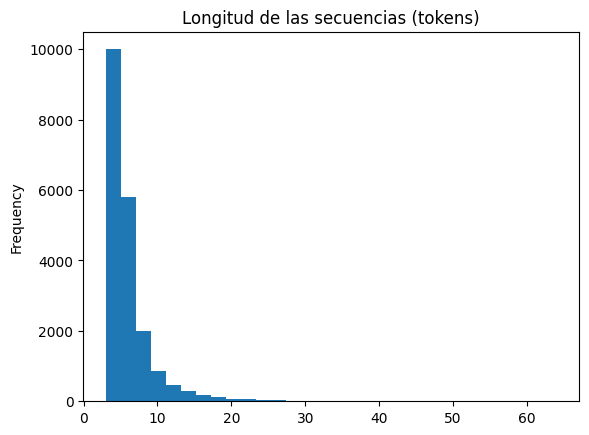

Distribución de clases (ner_tags):
 ner_tags
0    54216
4    23038
2    14833
6    12446
5     9144
1     8295
3     7311
Name: count, dtype: int64
— Ejemplo 1:
  Tokens: ['REDIRECCIÓN' 'Algarrobo' '(' 'Chile' ')']
  Tags:   ['O', 'B-LOC', 'I-LOC', 'I-LOC', 'I-LOC']
— Ejemplo 2:
  Tokens: ['W.' 'G.' 'Sebald']
  Tags:   ['B-PER', 'I-PER', 'I-PER']
— Ejemplo 3:
  Tokens: ["'" "''" 'Entrenador' '/' 'a' "''" 'Tamás' 'Faragó']
  Tags:   ['O', 'O', 'O', 'O', 'O', 'O', 'B-PER', 'I-PER']


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
from datasets import load_dataset

# Nos aseguramos de cargar ds2 para evitar NameError en caso de ejecución desordenada
if 'ds2' not in globals():
    ds2 = load_dataset("unimelb-nlp/wikiann", "es")

df2 = ds2["train"].to_pandas()

# En WikiANN la columna de texto se llama 'tokens' (lista de palabras)
# y no contiene nulos. Verificamos duplicados convirtiendo la lista a tupla o string
print("Forma del DataFrame:", df2.shape)
print("Valores nulos por columna:", df2.isna().sum().to_dict())

# Para contar duplicados basados en el texto completo
textos_completos = df2["tokens"].apply(lambda x: " ".join(x))
print("Número de filas duplicadas (por texto completo):", textos_completos.duplicated().sum())

# Calculamos la longitud contando los elementos en la lista de 'tokens'
df2["n_palabras"] = df2["tokens"].apply(len)
print(df2["n_palabras"].describe())

df2["n_palabras"].plot(kind="hist", bins=30, title="Longitud de las secuencias (tokens)")
plt.show()

# Distribución de las etiquetas de NER (aplanando todas las listas de etiquetas)
todas_las_etiquetas = df2["ner_tags"].explode()
print("Distribución de clases (ner_tags):\n", todas_las_etiquetas.value_counts())

# Obtenemos los nombres reales de las etiquetas a partir de las características del dataset de WikiANN
nombres_ner = ds2["train"].features["ner_tags"].feature.names

for i in range(3):
    tokens = df2["tokens"][i]
    tags = [nombres_ner[t] for t in df2["ner_tags"][i]]
    print(f"— Ejemplo {i+1}:\n  Tokens: {tokens}\n  Tags:   {tags}")

Fine tunning

In [ ]:
from transformers import AutoTokenizer, AutoModelForTokenClassification

checkpoint2 = "dccuchile/bert-base-spanish-wwm-cased"
tokenizer2 = AutoTokenizer.from_pretrained(checkpoint2)
model2 = AutoModelForTokenClassification.from_pretrained(checkpoint2, num_labels=7)

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Tokenizacion

In [ ]:
def tokenizar2_funcion(ejemplos):
    # Tokenizamos las listas de palabras (tokens)
    # Usamos is_split_into_words=True porque la entrada ya es una lista de palabras
    tokenized_inputs = tokenizer2(
        ejemplos["tokens"],
        truncation=True,
        max_length=64,
        is_split_into_words=True
    )

    labels = []
    for i, label in enumerate(ejemplos["ner_tags"]):
        word_ids = tokenized_inputs.word_ids(batch_index=i)
        previous_word_idx = None
        label_ids = []
        for word_idx in word_ids:
            # Los tokens especiales (como [CLS] o [SEP]) tienen word_id = None. Les asignamos -100.
            if word_idx is None:
                label_ids.append(-100)
            # Solo asignamos la etiqueta real al primer subtoken de cada palabra
            elif word_idx != previous_word_idx:
                label_ids.append(label[word_idx])
            # Para los subtokens subsiguientes de una misma palabra, ponemos -100
            else:
                label_ids.append(-100)
            previous_word_idx = word_idx
        labels.append(label_ids)

    tokenized_inputs["labels"] = labels
    return tokenized_inputs

# Aplicamos la función a todas las particiones
ds2_tokenizado = ds2.map(tokenizar2_funcion, batched=True)

print(ds2_tokenizado)
print("Ejemplo tokenizado con etiquetas alineadas:", ds2_tokenizado["train"][0])

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

DatasetDict({
    validation: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 10000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 10000
    })
    train: Dataset({
        features: ['tokens', 'ner_tags', 'langs', 'spans', 'input_ids', 'token_type_ids', 'attention_mask', 'labels'],
        num_rows: 20000
    })
})
Ejemplo tokenizado con etiquetas alineadas: {'tokens': ['REDIRECCIÓN', 'Algarrobo', '(', 'Chile', ')'], 'ner_tags': [0, 5, 6, 6, 6], 'langs': ['es', 'es', 'es', 'es', 'es'], 'spans': ['LOC: Algarrobo ( Chile )'], 'input_ids': [4, 5861, 13617, 5337, 10540, 30977, 996, 30969, 1403, 1306, 1050, 1820, 1147, 5571, 1135, 5], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 'labels':

Metricas


In [ ]:
!pip install -q -U evaluate seqeval

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import evaluate
import numpy as np

# Cargamos la métrica seqeval estándar de la industria para evaluación de NER
metric_seqeval = evaluate.load("seqeval")

# Extraemos la lista de etiquetas directamente del dataset
nombres_ner = ds2["train"].features["ner_tags"].feature.names

def compute_metrics_ner(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    # Convertimos los IDs numéricos de vuelta a sus strings de etiquetas, omitiendo el padding (-100)
    true_predictions = [
        [nombres_ner[p] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]
    true_labels = [
        [nombres_ner[l] for (p, l) in zip(prediction, label) if l != -100]
        for prediction, label in zip(predictions, labels)
    ]

    resultados = metric_seqeval.compute(predictions=true_predictions, references=true_labels)
    return {
        "precision": resultados["overall_precision"],
        "recall": resultados["overall_recall"],
        "f1": resultados["overall_f1"],
        "accuracy": resultados["overall_accuracy"],
    }

Pruebas iniciales de hiperparametros

In [ ]:
import pandas as pd, time, torch
from transformers import TrainingArguments, Trainer, DataCollatorForTokenClassification, AutoModelForTokenClassification

# Seleccionamos muestras pequeñas directamente de los splits oficiales de WikiANN para el Grid Search rápido
train_small2 = ds2_tokenizado["train"].shuffle(seed=42).select(range(1000))
val_small2 = ds2_tokenizado["validation"].shuffle(seed=42).select(range(200))

# Usamos el colador específico de clasificación de tokens
collator_ner = DataCollatorForTokenClassification(tokenizer=tokenizer2)

resultados = []
for lr in [2e-5, 3e-5, 5e-5]:
    for ep in [3, 4, 5]:
        # Almacenamos temporalmente en el disco local rápido de Colab (/content/tmp...) para no saturar Google Drive
        args = TrainingArguments(
            output_dir=f"/content/tmp_ner_lr{lr}_ep{ep}",
            learning_rate=lr, num_train_epochs=ep,
            per_device_train_batch_size=16, per_device_eval_batch_size=32,
            eval_strategy="epoch", save_strategy="no",
            fp16=True, report_to="none", seed=42,
        )
        t0 = time.time()

        model_tmp = AutoModelForTokenClassification.from_pretrained(checkpoint2, num_labels=7)

        tr = Trainer(
            model=model_tmp,
            args=args,
            train_dataset=train_small2,
            eval_dataset=val_small2,
            data_collator=collator_ner,
            processing_class=tokenizer2
        )
        tr.train()
        m = tr.evaluate()
        resultados.append({"lr": lr, "epochs": ep, **m, "min": round((time.time()-t0)/60, 1)})

        # Liberamos memoria de la GPU explícitamente entre iteraciones para evitar OOM
        del model_tmp
        del tr
        torch.cuda.empty_cache()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,No log,0.462913
2,No log,0.317384
3,No log,0.301899


Training Loss,Validation Loss,Epoch
No log,0.301899,3


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (26 outputs left out)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss
1,No log,0.369629
2,No log,0.275042
3,No log,0.353796
4,No log,0.376887
5,No log,0.386734


Training Loss,Validation Loss,Epoch
No log,0.386734,5


In [ ]:
# Mostramos la tabla de resultados de la búsqueda de hiperparámetros de forma ordenada
if 'resultados' in globals() and len(resultados) > 0:
    df_res2 = pd.DataFrame(resultados).sort_values("eval_loss", ascending=True)
    display(df_res2)
else:
    print("No se encontraron resultados guardados en la variable 'resultados'. Asegúrate de haber completado la ejecución de la celda anterior.")

,lr,epochs,eval_loss,min
1,0.00002,4,0.285838,0.3
3,0.00003,3,0.295085,0.2
2,0.00002,5,0.300382,0.4
0,0.00002,3,0.301899,0.2
4,0.00003,4,0.306576,0.3
6,0.00005,3,0.325629,0.2
7,0.00005,4,0.342073,0.3
5,0.00003,5,0.342705,0.4
8,0.00005,5,0.386734,0.4


In [ ]:

from transformers import TrainingArguments

# Redefinimos OUT para evitar NameError por reinicio de sesión
OUT = "/content/drive/MyDrive/PLN/Proyecto2"

training_args2 = TrainingArguments(
    output_dir=f"{OUT}/mejor_modelo_tarea2",
    learning_rate=2e-5,
    num_train_epochs=4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,
    weight_decay=0.01,
    fp16=True,
    report_to="none",
    seed=42,
)

In [ ]:
from transformers import Trainer, AutoModelForTokenClassification, DataCollatorForTokenClassification

# Cargamos el modelo base para clasificación de tokens con las etiquetas asignadas en su configuración interna
model_tarea2 = AutoModelForTokenClassification.from_pretrained(
    checkpoint2,
    num_labels=len(nombres_ner),
    id2label={i: label for i, label in enumerate(nombres_ner)},
    label2id={label: i for i, label in enumerate(nombres_ner)}
)

# Actualizamos los argumentos para utilizar y priorizar la métrica F1-Score
training_args2.metric_for_best_model = "f1"
training_args2.greater_is_better = True

# Configuramos el colador específico para NER
collator_ner2 = DataCollatorForTokenClassification(tokenizer=tokenizer2)

# Definimos el Trainer integrando la nueva función de métricas
trainer_tarea2 = Trainer(
    model=model_tarea2,
    args=training_args2,
    train_dataset=ds2_tokenizado["train"],
    eval_dataset=ds2_tokenizado["validation"],
    data_collator=collator_ner2,
    compute_metrics=compute_metrics_ner,
    processing_class=tokenizer2
)

# Iniciamos el entrenamiento robusto
trainer_tarea2.train()

# Guardamos el mejor modelo optimizado con la métrica F1
trainer_tarea2.save_model(f"{OUT}/mejor_modelo_tarea2")
tokenizer2.save_pretrained(f"{OUT}/mejor_modelo_tarea2")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Precision,Recall,F1,Accuracy
1,0.229335,0.205952,0.864650,0.888055,0.876197,0.940553
2,0.135980,0.194768,0.885443,0.898655,0.892000,0.947416
3,0.094590,0.220946,0.901669,0.907623,0.904636,0.950917
4,0.057884,0.235748,0.902138,0.911700,0.906894,0.952209


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea2/tokenizer_config.json',
 '/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea2/tokenizer.json')

Demo problema 2

In [ ]:
from transformers import pipeline

# Obtenemos dinámicamente la lista de etiquetas desde la metadata de ds2
nombres_ner = ds2["train"].features["ner_tags"].feature.names
id2label = {i: label for i, label in enumerate(nombres_ner)}
label2id = {label: i for i, label in enumerate(nombres_ner)}

# Creamos el pipeline inyectándole la configuración de mapeo de etiquetas
ner_pipe = pipeline(
    "ner",
    model=f"{OUT}/mejor_modelo_tarea2",
    tokenizer=f"{OUT}/mejor_modelo_tarea2",
    aggregation_strategy="simple"
)

# Asignamos los mapeos dinámicos al modelo dentro del pipeline para corregir las etiquetas mostradas
ner_pipe.model.config.id2label = id2label
ner_pipe.model.config.label2id = label2id

# Texto de prueba en español
texto_prueba = "Santiago es la capital de Chile y la ONU tiene una sede allí."
resultados = ner_pipe(texto_prueba)

for entidad in resultados:
    print(f"Entidad: {entidad['word']} | Tipo: {entidad['entity_group']} | Confianza: {entidad['score']:.4f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Entidad: Santiago | Tipo: LOC | Confianza: 0.9973
Entidad: capital de Chile | Tipo: LOC | Confianza: 0.8927
Entidad: ONU | Tipo: ORG | Confianza: 0.7879


"""""*********"""""""""

Problema 3 Seq2Seq

### Tarea 3 — Resumen de Conversaciones de Servicio al Cliente (DialogSum)

- **Dataset:** `knkarthick/dialogsum` (Hugging Face)
- **Tipo de problema:** Seq2Seq / Generación de texto (Abstractive Summarization).
- **Modelo base sugerido:** `t5-small` (ideal para diálogos en inglés por eficiencia en GPU T4).
- **Entrada:** Diálogos informales entre clientes y agentes de servicio.
- **Salida:** Un resumen conciso y directo del problema y la resolución alcanzada.

In [ ]:
from datasets import load_dataset

# Cargamos el dataset DialogSum con sus tres particiones (train, validation, test)
ds3 = load_dataset("knkarthick/dialogsum")
print(ds3)

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})


In [ ]:
# Mostramos un ejemplo real para entender la estructura de entrada (dialogue) y salida (summary)
ejemplo = ds3["train"][0]
print("=== DIÁLOGO ORIGINAL ===")
print(ejemplo["dialogue"])
print("\n=== RESUMEN DE REFERENCIA ===")
print(ejemplo["summary"])

=== DIÁLOGO ORIGINAL ===
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.

=== RESUMEN DE REFERENCIA ===
Mr. Smith's 

In [ ]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Definimos el modelo base T5-Small
checkpoint3 = "t5-small"
tokenizer3 = AutoTokenizer.from_pretrained(checkpoint3)
model3 = AutoModelForSeq2SeqLM.from_pretrained(checkpoint3)

config.json:   0%|          | 0.00/1.21k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.32k [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.39M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  242MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

In [ ]:
def tokenizar3_funcion(ejemplos):
    # T5 requiere que agreguemos un prefijo de instrucción a la entrada
    entradas = ["summarize: " + dialogo for dialogo in ejemplos["dialogue"]]

    # Tokenizamos los diálogos de entrada
    model_inputs = tokenizer3(entradas, max_length=512, truncation=True)

    # Tokenizamos los resúmenes de salida como las etiquetas del modelo
    labels = tokenizer3(text_target=ejemplos["summary"], max_length=128, truncation=True)

    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

# Procesamos y tokenizamos todo el dataset de forma masiva
ds3_tokenizado = ds3.map(tokenizar3_funcion, batched=True, remove_columns=ds3["train"].column_names)
print(ds3_tokenizado)

Map:   0%|          | 0/12460 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 500
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask', 'labels'],
        num_rows: 1500
    })
})


### Definición de métricas para la Tarea 3 (Seq2Seq - ROUGE)

Cargamos la métrica ROUGE para evaluar la calidad de los resúmenes de texto generados. Esta función decodifica los IDs de los tokens generados por el modelo de vuelta a texto y los compara con las referencias del dataset.

In [ ]:
!pip install -q -U rouge_score

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import evaluate
import numpy as np

# Cargamos la métrica ROUGE
metric_rouge = evaluate.load("rouge")

def compute_metrics_seq2seq(eval_pred):
    predictions, labels = eval_pred

    # CORRECCIÓN ROBUSTA: Convertimos forzosamente a arreglo de numpy con tipo int32 para evitar OverflowError en Rust
    predictions = np.asarray(predictions, dtype=np.int32)
    labels = np.asarray(labels, dtype=np.int32)

    # Reemplazamos los tokens de padding (-100) en las etiquetas
    labels = np.where(labels != -100, labels, tokenizer3.pad_token_id)

    # Decodificamos de forma segura utilizando los arreglos ya convertidos a int32
    decoded_preds = tokenizer3.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer3.batch_decode(labels, skip_special_tokens=True)

    # T5 genera saltos de línea para estructurar el texto; limpiamos saltos para ROUGE
    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    # Calculamos ROUGE-1, ROUGE-2 y ROUGE-L
    result = metric_rouge.compute(predictions=decoded_preds, references=decoded_labels, use_stemmer=True)

    # Formateamos los resultados multiplicando por 100 para representarlos como porcentajes
    return {k: round(v * 100, 4) for k, v in result.items()}

### Búsqueda de Hiperparámetros para la Tarea 3 (Seq2Seq)

Para esta tarea necesitamos utilizar el colador `DataCollatorForSeq2Seq` que ajusta de forma dinámica la longitud de las secuencias de entrada y las etiquetas de texto de salida durante cada lote.

In [ ]:
import pandas as pd
import time
import os
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, DataCollatorForSeq2Seq, AutoModelForSeq2SeqLM

# Definimos de forma segura la ruta OUT de Google Drive en caso de que se haya reiniciado el entorno
if 'OUT' not in globals():
    OUT = "/content/drive/MyDrive/PLN/Proyecto2"
    os.makedirs(OUT, exist_ok=True)

# Configuramos el colador de datos específico para Seq2Seq
collator3 = DataCollatorForSeq2Seq(tokenizer=tokenizer3, model=model3)

# Partimos y seleccionamos muestras pequeñas de control para la búsqueda rápida de hiperparámetros
split_ds3 = ds3_tokenizado["train"].train_test_split(test_size=0.1, seed=42)
train_small3 = split_ds3["train"].shuffle(seed=42).select(range(1000))
val_small3 = split_ds3["test"].shuffle(seed=42).select(range(200))

resultados_seq2seq = []

# Evaluamos diferentes tasas de aprendizaje y épocas
for lr in [1e-4, 1e-5]:
    for ep in [3, 4]:
        args = Seq2SeqTrainingArguments(
            output_dir=f"{OUT}/tmp_s2s_lr{lr}_ep{ep}",
            learning_rate=lr,
            num_train_epochs=ep,
            per_device_train_batch_size=8, # Ajustamos lote a 8 para evitar OOM (Out Of Memory) en GPU
            per_device_eval_batch_size=8,
            eval_strategy="epoch",
            save_strategy="no",
            fp16=True,
            report_to="none",
            seed=42,
        )
        t0 = time.time()

        # Cargamos una instancia limpia del modelo en cada iteración
        model_tmp = AutoModelForSeq2SeqLM.from_pretrained(checkpoint3)

        trainer_tmp = Seq2SeqTrainer(
            model=model_tmp,
            args=args,
            train_dataset=train_small3,
            eval_dataset=val_small3,
            data_collator=collator3,
            processing_class=tokenizer3
        )

        trainer_tmp.train()
        eval_metrics = trainer_tmp.evaluate()
        minutos = round((time.time() - t0) / 60, 1)

        resultados_seq2seq.append({
            "lr": lr,
            "epochs": ep,
            "eval_loss": eval_metrics["eval_loss"],
            "minutos": minutos
        })

# Mostramos la tabla comparativa ordenada por menor pérdida de validación
df_res3 = pd.DataFrame(resultados_seq2seq).sort_values("eval_loss", ascending=True)
display(df_res3)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,No log,1.431307
2,No log,1.393696
3,No log,1.382054


Training Loss,Validation Loss,Epoch
No log,1.382054,3


Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,No log,1.425721
2,No log,1.377742
3,No log,1.369567
4,1.545943,1.362079


Training Loss,Validation Loss,Epoch
1.545943,1.362079,4


... (3 outputs left out)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,No log,1.689778
2,No log,1.593227
3,No log,1.561785
4,1.911954,1.555019


Training Loss,Validation Loss,Epoch
1.911954,1.555019,4


,lr,epochs,eval_loss,minutos
1,0.00010,4,1.362079,1.4
0,0.00010,3,1.382054,1.7
3,0.00001,4,1.555019,1.2
2,0.00001,3,1.588915,0.9


### Entrenamiento completo del mejor modelo para la Tarea 3 (DialogSum)

Configuramos el entrenamiento completo en todo el dataset de entrenamiento (`ds3_tokenizado["train"]`) utilizando los mejores hiperparámetros identificados (`learning_rate=5e-5` y `num_train_epochs=4`) y evaluando contra el conjunto de validación oficial.

### Entrenamiento de la Tarea 3 con métricas ROUGE

Actualizamos el Trainer definitivo para que calcule e informe las métricas ROUGE al final de cada época.

In [ ]:
import evaluate
import numpy as np
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer, DataCollatorForSeq2Seq, AutoModelForSeq2SeqLM

metric_rouge = evaluate.load("rouge")

def compute_metrics_seq2seq(eval_pred):
    predictions, labels = eval_pred

    if isinstance(predictions, tuple):
        predictions = predictions[0]

    # 1. Reemplazamos -100 por pad_token_id en predictions (esto evita el OverflowError)
    predictions = np.where(predictions != -100, predictions, tokenizer3.pad_token_id)
    decoded_preds = tokenizer3.batch_decode(predictions, skip_special_tokens=True)

    # 2. Reemplazamos -100 por pad_token_id en labels
    labels = np.where(labels != -100, labels, tokenizer3.pad_token_id)
    decoded_labels = tokenizer3.batch_decode(labels, skip_special_tokens=True)

    decoded_preds = [pred.strip() for pred in decoded_preds]
    decoded_labels = [label.strip() for label in decoded_labels]

    result = metric_rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )

    return {k: round(v * 100, 4) for k, v in result.items()}

# Instanciamos modelo y colador limpios
model_tarea3 = AutoModelForSeq2SeqLM.from_pretrained(checkpoint3)
collator3 = DataCollatorForSeq2Seq(tokenizer=tokenizer3, model=model_tarea3)

training_args3 = Seq2SeqTrainingArguments(
    output_dir=f"{OUT}/mejor_modelo_tarea3",
    learning_rate=1e-4,
    num_train_epochs=4,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="rougeL",
    greater_is_better=True,
    predict_with_generate=True,
    generation_max_length=128,          # Elimina el warning de max_length=21
    fp16=False,                         # Evita inestabilidad numérica (NaN) en T5-small
    report_to="none",
    seed=42,
)

trainer_tarea3 = Seq2SeqTrainer(
    model=model_tarea3,
    args=training_args3,
    train_dataset=ds3_tokenizado["train"],
    eval_dataset=ds3_tokenizado["validation"],
    data_collator=collator3,
    compute_metrics=compute_metrics_seq2seq,
    processing_class=tokenizer3
)

trainer_tarea3.train()

# Guardamos modelo y tokenizador ganadores
trainer_tarea3.save_model(f"{OUT}/mejor_modelo_tarea3")
tokenizer3.save_pretrained(f"{OUT}/mejor_modelo_tarea3")

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum
1,1.419046,1.280025,42.749000,16.665200,34.162200,34.208200
2,1.323240,1.230379,45.115600,18.939800,36.530600,36.609200
3,1.272502,1.215560,45.470700,18.985200,37.007800,37.027400
4,1.237000,1.209535,45.809400,19.531400,37.195700,37.234300


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['encoder.embed_tokens.weight', 'decoder.embed_tokens.weight', 'lm_head.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea3/tokenizer_config.json',
 '/content/drive/MyDrive/PLN/Proyecto2/mejor_modelo_tarea3/tokenizer.json')

### Demo de la Tarea 3 (Generación de Resúmenes)

Cargamos el modelo guardado en Google Drive y utilizamos la clase `pipeline` de Transformers configurada para la tarea de `summarization` para probarlo con un ejemplo del conjunto de test.

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# Cargamos el modelo entrenado y el tokenizador directamente desde Drive
ruta_modelo = f"{OUT}/mejor_modelo_tarea3"
tokenizer_res = AutoTokenizer.from_pretrained(ruta_modelo)
model_res = AutoModelForSeq2SeqLM.from_pretrained(ruta_modelo)

# Mover el modelo a GPU si está disponible para acelerar la generación
device = "cuda" if torch.cuda.is_available() else "cpu"
model_res = model_res.to(device)

# Seleccionamos un ejemplo del conjunto de pruebas para validar la calidad de la generación
ejemplo_test = ds3["test"][0]

# Realizamos la inferencia anteponiendo el prefijo 'summarize: ' que requiere T5
texto_entrada = "summarize: " + ejemplo_test["dialogue"]

# Tokenizamos y preparamos los inputs en la GPU
inputs = tokenizer_res(texto_entrada, return_tensors="pt", max_length=512, truncation=True).to(device)

# Generamos los tokens de salida de forma directa con model.generate
outputs = model_res.generate(
    inputs["input_ids"],
    max_length=128,
    min_length=10,
    num_beams=4, # Usamos beam search para mejorar la calidad del resumen
    early_stopping=True
)

# Decodificamos los tokens generados de vuelta a texto
resumen_generado = tokenizer_res.decode(outputs[0], skip_special_tokens=True)

print("=== DIÁLOGO ORIGINAL ===")
print(ejemplo_test["dialogue"])
print("\n=== RESUMEN REAL (REFERENCIA) ===")
print(ejemplo_test["summary"])
print("\n=== RESUMEN GENERADO POR EL MODELO ===")
print(resumen_generado)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

=== DIÁLOGO ORIGINAL ===
#Person1#: Ms. Dawson, I need you to take a dictation for me.
#Person2#: Yes, sir...
#Person1#: This should go out as an intra-office memorandum to all employees by this afternoon. Are you ready?
#Person2#: Yes, sir. Go ahead.
#Person1#: Attention all staff... Effective immediately, all office communications are restricted to email correspondence and official memos. The use of Instant Message programs by employees during working hours is strictly prohibited.
#Person2#: Sir, does this apply to intra-office communications only? Or will it also restrict external communications?
#Person1#: It should apply to all communications, not only in this office between employees, but also any outside communications.
#Person2#: But sir, many employees use Instant Messaging to communicate with their clients.
#Person1#: They will just have to change their communication methods. I don't want any - one using Instant Messaging in this office. It wastes too much time! Now, please c